Praktikum 6 - ANN pada dataset lagu Spotify (32.833 track, 9 fitur audio).

Dataset: data/spotify_songs.csv (TidyTuesday "Spotify Songs", setara Micro Spotify
Kaggle yang dipakai jobsheet; kolom fitur yang dipakai identik).
Annoy tidak bisa di-build di mesin ini -> dipadankan faiss.IndexIVFFlat.
hnswlib tidak bisa di-build -> dipadankan faiss.IndexHNSWFlat.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("p6_spotify_ann.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js06-ann-approximate-nearest-neighbors\praktikum-6


In [2]:
from pathlib import Path
import csv
import time

import numpy as np
import pandas as pd
import faiss
import matplotlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

OUT = Path(__file__).parent / "output"
OUT.mkdir(exist_ok=True)
DATA = Path(__file__).resolve().parents[1] / "data" / "spotify_songs.csv"
FEATURES = ["danceability", "energy", "loudness", "speechiness",
            "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
K, NQ = 10, 2000

Dataset: 32833 track x 9 fitur -> (32833, 9)


metode                  build_s  ms/query recall@10
Exact (sklearn brute)      0.00    0.1101     1.000
Annoy -> faiss IVF         0.15    0.0144     0.989
HNSW -> faiss HNSW         0.86    0.0409     0.989
FAISS IVF (nprobe=10)      0.16    0.0130     0.989

Top-5 tetangga untuk track pertama:
Query: I Don't Care (with Justin Bieber) - Loud Luxury Remix - Ed Sheeran
  Exact (sklearn brute)  [0, 29684, 29734, 4959, 29713]
      I Don't Care (with Justin Bieber) - Lo - Ed Sheeran
      I Don't Care (with Justin Bieber) - Lo - Ed Sheeran
      I Miss You (feat. Julia Michaels) - Ca - Clean Bandit
      Name & Number - Shift K3Y
      Rise - TV Noise Ibiza Mix - Jonas Blue
  Annoy -> faiss IVF     [0, 29684, 29734, 4959, 29713]
      I Don't Care (with Justin Bieber) - Lo - Ed Sheeran
      I Don't Care (with Justin Bieber) - Lo - Ed Sheeran
      I Miss You (feat. Julia Michaels) - Ca - Clean Bandit
      Name & Number - Shift K3Y
      Rise - TV Noise Ibiza Mix - Jonas Blue
  HNSW -> f

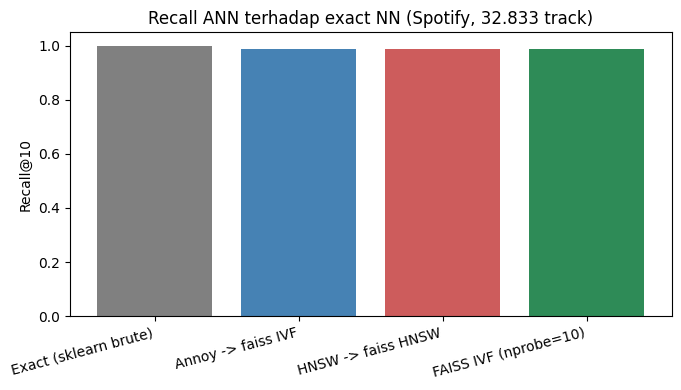

In [3]:
def recall(pred, gt):
    return float(np.mean([len(set(p) & set(g)) / K for p, g in zip(pred, gt)]))


df = pd.read_csv(DATA)
X = StandardScaler().fit_transform(df[FEATURES].values).astype(np.float32)
Q = X[:NQ]
print(f"Dataset: {len(df)} track x {len(FEATURES)} fitur -> {X.shape}")

t0 = time.perf_counter()
nn = NearestNeighbors(n_neighbors=K, algorithm="brute", metric="euclidean").fit(X)
D_e, I_e = nn.kneighbors(Q)
t_exact = (time.perf_counter() - t0) / NQ * 1000

d = X.shape[1]
t0 = time.perf_counter()
ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(d), d, 100, faiss.METRIC_L2)
ivf.train(X)
ivf.add(X)
ivf.nprobe = 10
t_ivf_build = time.perf_counter() - t0
t0 = time.perf_counter()
D_ivf, I_ivf = ivf.search(Q, K)
t_ivf = (time.perf_counter() - t0) / NQ * 1000

t0 = time.perf_counter()
hnsw = faiss.IndexHNSWFlat(d, 16)
hnsw.hnsw.efConstruction = 200
hnsw.add(X)
t_hnsw_build = time.perf_counter() - t0
hnsw.hnsw.efSearch = 200
t0 = time.perf_counter()
D_hn, I_hn = hnsw.search(Q, K)
t_hn = (time.perf_counter() - t0) / NQ * 1000

t0 = time.perf_counter()
q2 = faiss.IndexFlatL2(d)
ivf2 = faiss.IndexIVFFlat(q2, d, 100, faiss.METRIC_L2)
ivf2.train(X)
ivf2.add(X)
ivf2.nprobe = 10
t_f2_build = time.perf_counter() - t0
t0 = time.perf_counter()
D_f2, I_f2 = ivf2.search(Q, K)
t_f2 = (time.perf_counter() - t0) / NQ * 1000

res = [("Exact (sklearn brute)", 0.0, t_exact, I_e, 1.0),
       ("Annoy -> faiss IVF", t_ivf_build, t_ivf, I_ivf, recall(I_ivf, I_e)),
       ("HNSW -> faiss HNSW", t_hnsw_build, t_hn, I_hn, recall(I_hn, I_e)),
       ("FAISS IVF (nprobe=10)", t_f2_build, t_f2, I_f2, recall(I_f2, I_e))]

print(f"{'metode':22s} {'build_s':>8s} {'ms/query':>9s} {'recall@10':>9s}")
rows = []
for name, b, q, I, rec in res:
    print(f"{name:22s} {b:8.2f} {q:9.4f} {rec:9.3f}")
    rows.append([name, round(b, 3), round(q, 4), round(rec, 3)])

print("\nTop-5 tetangga untuk track pertama:")
first = df.iloc[0]
print(f"Query: {first['track_name']} - {first['track_artist']}")
for name, *_ , I, _rec in res:
    ids = I[0][:5]
    titles = [" - ".join([str(df.iloc[i]["track_name"])[:38], str(df.iloc[i]["track_artist"])[:18]]) for i in ids]
    print(f"  {name:22s} {list(map(int, ids))}")
    for t in titles:
        print(f"      {t}")

with open(OUT / "hasil_tabel.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["metode", "build_s", "ms_per_query", "recall@10"])
    w.writerows(rows)
    for name, _, _, I, _r in res:
        w.writerow([name + " top5", "", "", list(map(int, I[0][:5]))])

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([r[0] for r in rows], [r[3] for r in rows], color=["gray", "steelblue", "indianred", "seagreen"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall@10")
ax.set_title("Recall ANN terhadap exact NN (Spotify, 32.833 track)")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
fig.savefig(OUT / "p6_recall.png", dpi=120)